# 1. Entendimento do Negócio e dos Dados

In [ ]:
import pandas as pd
df = pd.read_csv('datatran2025.csv', sep=';', encoding='latin1')

In [ ]:
df_copy = df.copy() #criando uma cópia caso algo dê errado

In [ ]:
display(df) #exibe as 5 primeiras e ultimas linhas do df

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,652493,2025-01-01,quarta-feira,06:20:00,SP,116,225,GUARULHOS,Reação tardia ou ineficiente do condutor,Tombamento,...,0,0,1,1,2,"-23,48586772","-46,54075317",SPRF-SP,DEL01-SP,UOP01-DEL01-SP
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,"546,2",PENAFORTE,Pista esburacada,Colisão frontal,...,0,1,4,1,6,"-7,812288","-39,08333306",SPRF-CE,DEL05-CE,UOP03-DEL05-CE
2,652522,2025-01-01,quarta-feira,08:45:00,PR,369,"88,2",CORNELIO PROCOPIO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,2,0,3,2,"-23,182565","-50,637228",SPRF-PR,DEL07-PR,UOP05-DEL07-PR
3,652544,2025-01-01,quarta-feira,11:00:00,PR,116,74,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,...,0,4,0,1,2,"-25,36517687","-49,04223028",SPRF-PR,DEL01-PR,UOP02-DEL01-PR
4,652549,2025-01-01,quarta-feira,09:30:00,MG,251,471,FRANCISCO SA,Velocidade Incompatível,Colisão frontal,...,1,1,2,2,4,"-16,46801304","-43,43121303",SPRF-MG,DEL12-MG,UOP01-DEL12-MG
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72524,757462,2025-12-20,sábado,13:10:00,MG,381,"279,5",JAGUARACU,Acessar a via sem observar a presença dos outr...,Colisão transversal,...,0,1,0,2,2,"-19,607","-42,7611",SPRF-MG,DEL03-MG,UOP02-DEL03-MG
72525,757492,2025-09-27,sábado,13:50:00,SC,282,381,HERVAL DOESTE,Conversão proibida,Colisão transversal,...,1,0,2,2,3,"-27,2096","-51,50077",SPRF-SC,DEL07-SC,UOP05-DEL07-SC
72526,757593,2025-12-14,domingo,13:50:00,PE,104,62,CARUARU,Ausência de reação do condutor,Colisão transversal,...,0,2,0,1,2,"-8,25368","-35,97546",SPRF-PE,DEL02-PE,UOP01-DEL02-PE
72527,758175,2025-12-15,segunda-feira,15:50:00,SC,101,130,CAMBORIU,Condutor deixou de manter distância do veículo...,Colisão traseira,...,0,2,0,0,2,"-26,99305955","-48,6609548",SPRF-SC,DEL04-SC,UOP03-DEL04-SC


Abrindo as primeiras 1000 linhas do dataset no Excel, mostrou que:
- 'causa_acidente' tem vários valores diferentes
- 'tipo_acidente' tem 17 valores diferentes nas primeiras 1000 linhas
- 'classificacao_acidente' tem 3 valores diferentes (e 1 linha nula)
- 'condicao_metereologica' tem 8 valores diferentes

In [ ]:
df.info() #verificando valores nulos e infos do dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72529 entries, 0 to 72528
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id                      72529 non-null  int64 
 1   data_inversa            72529 non-null  object
 2   dia_semana              72529 non-null  object
 3   horario                 72529 non-null  object
 4   uf                      72529 non-null  object
 5   br                      72529 non-null  int64 
 6   km                      72529 non-null  object
 7   municipio               72529 non-null  object
 8   causa_acidente          72529 non-null  object
 9   tipo_acidente           72529 non-null  object
 10  classificacao_acidente  72528 non-null  object
 11  fase_dia                72529 non-null  object
 12  sentido_via             72529 non-null  object
 13  condicao_metereologica  72529 non-null  object
 14  tipo_pista              72529 non-null  object
 15  tr

In [ ]:
acidentes = pd.DataFrame({'Quantidade': df['classificacao_acidente'].value_counts(), 'Percentual(%)': (df['classificacao_acidente'].value_counts(normalize=True) * 100).round(2)}) #criei a variavel 'acidentes' e dividi os acidentes por quantidade e porcentagem
print(acidentes)

                        Quantidade  Percentual(%)
classificacao_acidente                           
Com Vítimas Feridas          56181          77.46
Sem Vítimas                  11138          15.36
Com Vítimas Fatais            5209           7.18


# Valores nulos
- São poucos valores nulos e em colunas que não afetarão a análise

In [ ]:
df[df['classificacao_acidente'].isnull()]

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,"546,2",PENAFORTE,Pista esburacada,Colisão frontal,...,0,1,4,1,6,"-7,812288","-39,08333306",SPRF-CE,DEL05-CE,UOP03-DEL05-CE


In [ ]:
df[df['regional'].isnull()]

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
49791,709927,2025-08-07,quinta-feira,07:30:00,DF,0,0,BRASILIA,Acessar a via sem observar a presença dos outr...,Colisão traseira,...,0,2,0,0,2,"-15,813622","-47,999228",NaN,NaN,NaN
54419,716752,2025-09-07,domingo,07:05:00,DF,0,0,BRASILIA,Reação tardia ou ineficiente do condutor,Colisão transversal,...,0,4,0,0,4,"-15,778198","-47,938563",NaN,NaN,NaN


In [ ]:
df[df['delegacia'].isnull()].head(5)

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
8905,702392,2025-07-04,sexta-feira,11:00:00,SE,0,0,ARACAJU,Desrespeitar a preferência no cruzamento,Colisão transversal,...,0,4,0,0,2,"-10,895147","-37,082538",SPRF-SE,NaN,NaN
10756,710006,2025-07-28,segunda-feira,10:20:00,PA,0,0,TAILANDIA,Ausência de reação do condutor,Colisão traseira,...,0,6,2,0,6,"-2,845897","-48,964221",SPRF-PA,NaN,NaN
22094,657145,2025-01-24,sexta-feira,22:05:00,RJ,0,0,NITEROI,Frear bruscamente,Colisão traseira,...,0,7,0,0,5,"-22,85996981","-43,10239261",SPRF-RJ,NaN,NaN
28458,666766,2025-02-21,sexta-feira,21:15:00,RJ,0,0,RIO DE JANEIRO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,7,0,0,2,"-22,806135","-43,355273",SPRF-RJ,NaN,NaN
30176,669357,2025-03-24,segunda-feira,18:30:00,RJ,0,0,RIO DE JANEIRO,Acumulo de areia ou detritos sobre o pavimento,Colisão frontal,...,0,3,0,0,1,"-22,80886","-43,341883",SPRF-RJ,NaN,NaN


In [ ]:
df[df['uop'].isnull()].head(5)

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
8905,702392,2025-07-04,sexta-feira,11:00:00,SE,0,0,ARACAJU,Desrespeitar a preferência no cruzamento,Colisão transversal,...,0,4,0,0,2,"-10,895147","-37,082538",SPRF-SE,NaN,NaN
10756,710006,2025-07-28,segunda-feira,10:20:00,PA,0,0,TAILANDIA,Ausência de reação do condutor,Colisão traseira,...,0,6,2,0,6,"-2,845897","-48,964221",SPRF-PA,NaN,NaN
22094,657145,2025-01-24,sexta-feira,22:05:00,RJ,0,0,NITEROI,Frear bruscamente,Colisão traseira,...,0,7,0,0,5,"-22,85996981","-43,10239261",SPRF-RJ,NaN,NaN
26594,664070,2025-02-06,quinta-feira,07:10:00,PR,0,0,LONDRINA,Semáforo com defeito,Colisão lateral sentido oposto,...,0,1,3,0,3,"-23,29642","-51,198939",SPRF-PR,DEL07-PR,NaN
28458,666766,2025-02-21,sexta-feira,21:15:00,RJ,0,0,RIO DE JANEIRO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,7,0,0,2,"-22,806135","-43,355273",SPRF-RJ,NaN,NaN


# Valores faltantes

In [ ]:
print("Valores duplicados:", df.duplicated().sum()) #linhas duplicadas

Valores duplicados: 0


In [ ]:
ids_duplicados = df['id'].duplicated().sum() #ids de acidentes duplicados
print(f"IDs duplicados: {ids_duplicados}")

IDs duplicados: 0


#2. Preparação dos Dados

1-

In [ ]:
colunas = ['pessoas', 'mortos', 'feridos_leves', 'feridos_graves', 'ilesos', 'ignorados', 'feridos']
df.loc[1, colunas] #mostra as colunas selecionadas da linha 1

,1
pessoas,6
mortos,1
feridos_leves,1
feridos_graves,0
ilesos,1
ignorados,4
feridos,1


In [ ]:
df.loc[1, 'classificacao_acidente'] = 'Com Vítimas Fatais' #altera a classificacao do acidente na linha de indice 1

2-

In [ ]:
df['gravidade'] = "Sem Classificação" #criando a nova coluna

df.loc[df['mortos'] > 0, 'gravidade'] = "Acidente fatal" #atribuindo valor as linhas da nova coluna
df.loc[(df['mortos'] == 0) & (df['feridos_graves'] > 0), 'gravidade'] = "Acidente grave"
df.loc[(df['mortos'] == 0) & (df['feridos_graves'] == 0), 'gravidade'] = "Acidente sem gravidade"

3-

In [ ]:
df['grave_ou_fatal'] = 0 #criando a variável-alvo
df.loc[(df['mortos'] > 0) | (df['feridos_graves'] > 0), 'grave_ou_fatal'] = 1

In [ ]:
print(pd.crosstab(df["gravidade"], df["grave_ou_fatal"]))
print(df["grave_ou_fatal"].value_counts(normalize=True))
#crosstab pra verificar se tem algum dado inconsistente

grave_ou_fatal              0      1
gravidade                           
Acidente fatal              0   5210
Acidente grave              0  15283
Acidente sem gravidade  52036      0
grave_ou_fatal
0    0.717451
1    0.282549
Name: proportion, dtype: float64


4-

In [ ]:
colunas_clean = ['dia_semana', 'causa_acidente', 'tipo_acidente', 'fase_dia', 'condicao_metereologica'] #variáveis preditoras

x = df[colunas_clean] #x = variáveis preditoras
y = df['grave_ou_fatal'] #y = variável-alvo

In [ ]:
for col in colunas_clean: #para cada coluna em colunas_clean
    print(col, x[col].nunique()) #exiba col (nome da coluna), x[col].nunique() (conta quantos valores diferentes existem nessa coluna)
    print(x[col].value_counts().head(10), "\n") #conta quantas vezes cada valor aparece e exibe apenas os 10 primeiros valores de maior frequência

dia_semana 7
dia_semana
sábado           11554
domingo          11470
sexta-feira      11197
segunda-feira    10285
quarta-feira      9556
quinta-feira      9405
terça-feira       9062
Name: count, dtype: int64 

causa_acidente 69
causa_acidente
Ausência de reação do condutor                               11469
Reação tardia ou ineficiente do condutor                     10799
Acessar a via sem observar a presença dos outros veículos     7097
Condutor deixou de manter distância do veículo da frente      4413
Velocidade Incompatível                                       4088
Manobra de mudança de faixa                                   4016
Ingestão de álcool pelo condutor                              3685
Demais falhas mecânicas ou elétricas                          3385
Transitar na contramão                                        2475
Condutor Dormindo                                             2116
Name: count, dtype: int64 

tipo_acidente 17
tipo_acidente
Colisão traseira         

5-

In [ ]:
#quantidade e proporção de grave/fatal e sem gravidade
print((y.value_counts()))
print((y.value_counts(normalize=True) * 100).round(2))

grave_ou_fatal
0    52036
1    20493
Name: count, dtype: int64
grave_ou_fatal
0    71.75
1    28.25
Name: proportion, dtype: float64


6-

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=50) #separando 20% pra teste e 80% pra treino

In [ ]:
#verificando quantidade dos treinos
print(x_train.shape)
print(y_train.shape)

(58023, 5)
(58023,)


In [ ]:
#verificando proporção dos treinos
print((x_train.value_counts(normalize=True) * 100).round(2))
print((y_train.value_counts(normalize=True) * 100).round(2))

dia_semana     causa_acidente                                             tipo_acidente                 fase_dia   condicao_metereologica
sexta-feira    Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia  Céu Claro                 0.53
segunda-feira  Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia  Céu Claro                 0.45
quarta-feira   Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia  Céu Claro                 0.42
quinta-feira   Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia  Céu Claro                 0.42
terça-feira    Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia  Céu Claro                 0.39
                                                                                                                                    

In [ ]:
#verificando quantidade dos testes
print(x_test.shape)
print(y_test.shape)

(14506, 5)
(14506,)


In [ ]:
#verificando proporção dos testes
print((x_test.value_counts(normalize=True) * 100).round(2))
print((y_test.value_counts(normalize=True) * 100).round(2))

dia_semana    causa_acidente                                             tipo_acidente                 fase_dia     condicao_metereologica
sexta-feira   Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia    Céu Claro                 0.45
terça-feira   Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia    Céu Claro                 0.45
sábado        Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia    Céu Claro                 0.43
quinta-feira  Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia    Céu Claro                 0.43
domingo       Acessar a via sem observar a presença dos outros veículos  Colisão transversal           Pleno dia    Céu Claro                 0.42
                                                                                                                              

In [ ]:
frequencias = df['causa_acidente'].value_counts()
print(frequencias.head(29)) #29 valores de maior frequência da coluna

causa_acidente
Ausência de reação do condutor                               11469
Reação tardia ou ineficiente do condutor                     10799
Acessar a via sem observar a presença dos outros veículos     7097
Condutor deixou de manter distância do veículo da frente      4413
Velocidade Incompatível                                       4088
Manobra de mudança de faixa                                   4016
Ingestão de álcool pelo condutor                              3685
Demais falhas mecânicas ou elétricas                          3385
Transitar na contramão                                        2475
Condutor Dormindo                                             2116
Ultrapassagem Indevida                                        1770
Trafegar com motocicleta (ou similar) entre as faixas         1325
Animais na Pista                                              1305
Desrespeitar a preferência no cruzamento                      1259
Avarias e/ou desgaste excessivo no pneu        

In [ ]:
frequencias = df['causa_acidente'].value_counts()
print(frequencias.tail(40)) #40 valores de menor frequência da coluna

causa_acidente
Demais falhas na via                                                            275
Condutor desrespeitou a iluminação vermelha do semáforo                         268
Carga excessiva e/ou mal acondicionada                                          256
Problema com o freio                                                            247
Pista esburacada                                                                232
Acumulo de óleo sobre o pavimento                                               228
Afundamento ou ondulação no pavimento                                           206
Curva acentuada                                                                 203
Suicídio (presumido)                                                            190
Condutor usando celular                                                         189
Estacionar ou parar em local proibido                                           182
Ausência de sinalização                                      

In [ ]:
frequencias_treino = x_train['causa_acidente'].value_counts() #quantas vezes cada causa aparece no treino

limite_minimo = 300 #tem q aparecer no minimo 300 vezes, senao vai pro grupo "Outros"

categorias_validas = frequencias_treino[frequencias_treino >= limite_minimo].index #filtra quais categorias atingiram ou passaram do limite

x_train['causa_acidente'] = x_train['causa_acidente'].apply( #percorre as linhas da coluna no treino
    lambda valor: valor if valor in categorias_validas else 'Outros' #mantém a categoria se aparecer mais q 300 vezes, senão troca por 'Outros'
)
x_test['causa_acidente'] = x_test['causa_acidente'].apply( #faz o mesmo para o conjunto de teste
    lambda valor: valor if valor in categorias_validas else 'Outros' #aplica a mesma regra do treino, evitando vazamento
)

In [ ]:
frequencias2 = df['tipo_acidente'].value_counts()
print(frequencias2.tail(17)) #40 valores de menor frequência da coluna

tipo_acidente
Colisão traseira                  14360
Saída de leito carroçável         10209
Colisão transversal                9306
Colisão lateral mesmo sentido      7885
Tombamento                         6351
Colisão com objeto                 5109
Colisão frontal                    4739
Queda de ocupante de veículo       3450
Atropelamento de Pedestre          3057
Colisão lateral sentido oposto     2152
Incêndio                           1771
Capotamento                        1373
Engavetamento                      1233
Atropelamento de Animal            1133
Eventos atípicos                    287
Derramamento de carga               107
Sinistro pessoal de trânsito          7
Name: count, dtype: int64


In [ ]:
frequencias3 = df['condicao_metereologica'].value_counts()
print(frequencias3.tail(9)) #40 valores de menor frequência da coluna

condicao_metereologica
Céu Claro           46375
Nublado             11435
Chuva                6438
Sol                  4201
Garoa/Chuvisco       2422
Ignorado             1000
Nevoeiro/Neblina      553
Vento                 104
Neve                    1
Name: count, dtype: int64


In [ ]:
frequencias_treino2 = x_train['tipo_acidente'].value_counts()

limite_minimo2 = 300

categorias_validas2 = frequencias_treino2[frequencias_treino2 >= limite_minimo2].index

x_train['tipo_acidente'] = x_train['tipo_acidente'].apply(
    lambda valor: valor if valor in categorias_validas2 else 'Outros'
)
x_test['tipo_acidente'] = x_test['tipo_acidente'].apply(
    lambda valor: valor if valor in categorias_validas2 else 'Outros'
)

In [ ]:
frequencias_treino3 = x_train['condicao_metereologica'].value_counts()

limite_minimo3 = 300

categorias_validas3 = frequencias_treino3[frequencias_treino3 >= limite_minimo3].index

x_train['condicao_metereologica'] = x_train['condicao_metereologica'].apply(
    lambda valor: valor if valor in categorias_validas3 else 'Outros'
)
x_test['condicao_metereologica'] = x_test['condicao_metereologica'].apply(
    lambda valor: valor if valor in categorias_validas3 else 'Outros'
)

7-

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False) #cria o codificador ignorando categorias desconhecidas no teste

colunas_categoricas = ['causa_acidente', 'tipo_acidente', 'condicao_metereologica', 'dia_semana', 'fase_dia']

x_train_encoded_array = encoder.fit_transform(x_train[colunas_categoricas]) #ajusta e transforma apenas o treino gerando uma matriz numérica
x_test_encoded_array = encoder.transform(x_test[colunas_categoricas]) #transforma o teste usando a regra aprendida no treino

nomes_colunas = encoder.get_feature_names_out(colunas_categoricas) #extrai os nomes gerados para cada nova coluna binária

x_train_encoded = pd.DataFrame(x_train_encoded_array, columns=nomes_colunas, index=x_train.index) #converte o array do treino em df mantendo o índice original
x_test_encoded = pd.DataFrame(x_test_encoded_array, columns=nomes_colunas, index=x_test.index) #converte o array do teste em df mantendo o índice original

#3. Modelagem

1-

Análise Exploratória

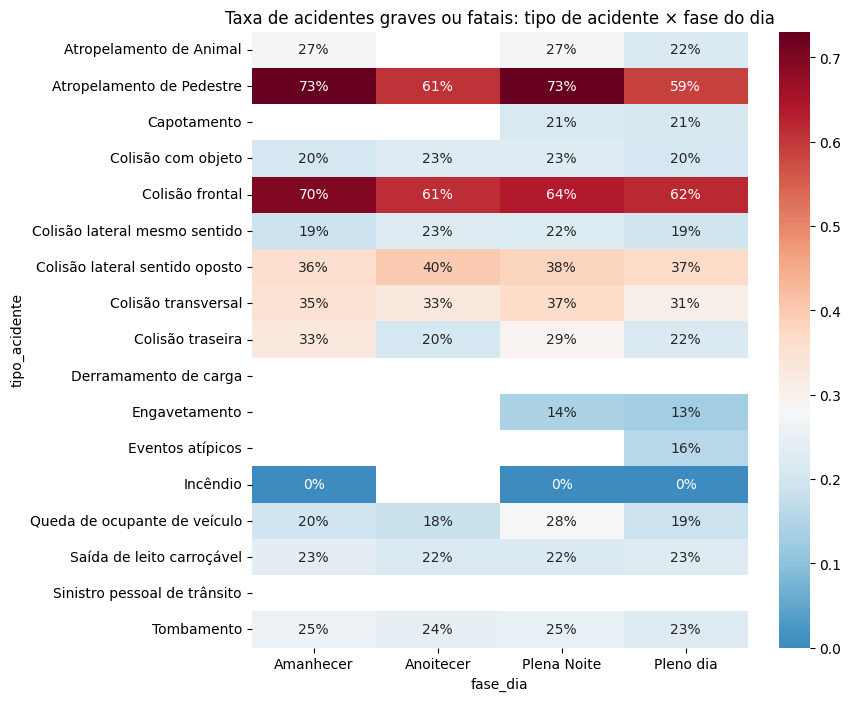

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#taxa de referência(todos os acidentes de 2025)
taxa_geral = df['grave_ou_fatal'].mean()

#taxa de gravidade por categoria ou combinação
def taxa_por(dados, colunas, minimo=100):
    tabela = (dados.groupby(colunas)['grave_ou_fatal']
                   .agg(total='count', graves_fatais='sum', taxa='mean')
                   .reset_index())
    tabela = tabela[tabela['total'] >= minimo].copy() #descarta amostras pequenas
    tabela['dif_pp'] = (tabela['taxa'] - taxa_geral) * 100 #diferença para a média
    tabela['razao'] = tabela['taxa'] / taxa_geral #qquantas vezes acima/abaixo da média
    return tabela.sort_values('taxa', ascending=False)

#par de variáveis
par = taxa_por(df, ['fase_dia', 'tipo_acidente'], minimo=100)

#mapa de calor da taxa por combinação
taxa = df.pivot_table(index='tipo_acidente', columns='fase_dia',
                      values='grave_ou_fatal', aggfunc='mean')
total = df.pivot_table(index='tipo_acidente', columns='fase_dia',
                       values='grave_ou_fatal', aggfunc='count')
taxa = taxa.where(total >= 100) #esconde células com poucos casos

plt.figure(figsize=(8, 8))
sns.heatmap(taxa, annot=True, fmt='.0%', cmap='RdBu_r', center=taxa_geral)
plt.title('Taxa de acidentes graves ou fatais: tipo de acidente × fase do dia')
plt.show()

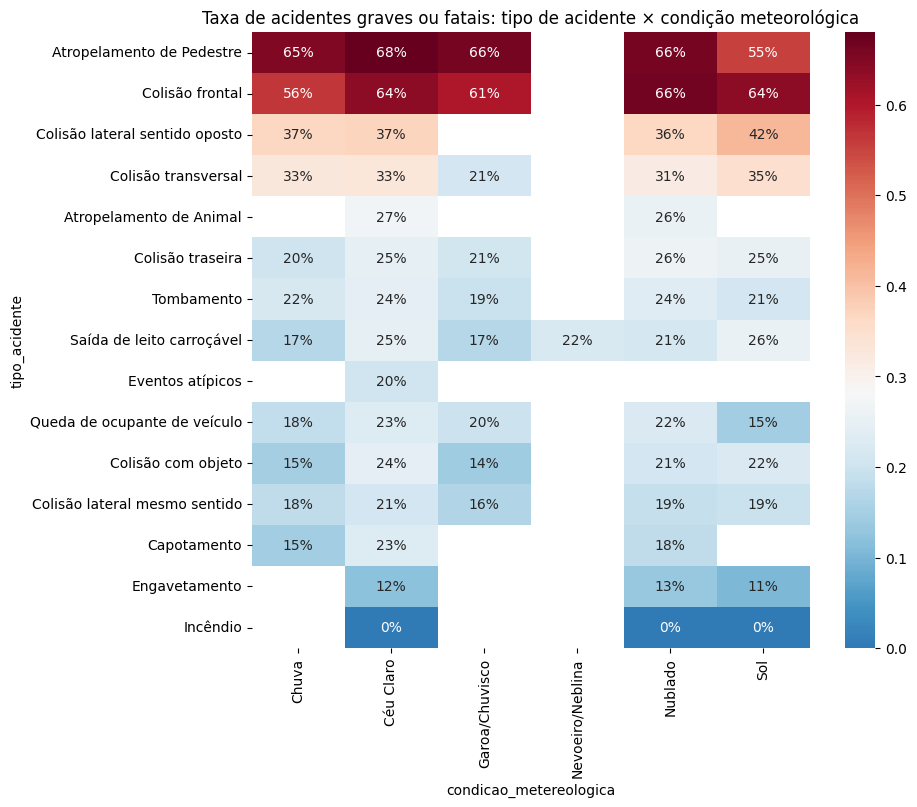

In [ ]:
def mapa_calor(dados, linha, coluna, minimo=100, titulo=None, tamanho=(9, 8)):
    taxa_pivot = dados.pivot_table(index=linha, columns=coluna,
                                   values='grave_ou_fatal', aggfunc='mean')
    total_pivot = dados.pivot_table(index=linha, columns=coluna,
                                    values='grave_ou_fatal', aggfunc='count')

    taxa_pivot = taxa_pivot.where(total_pivot >= minimo) #esconde células com poucos casos
    taxa_pivot = taxa_pivot.dropna(how='all').dropna(axis=1, how='all') #remove linhas/colunas vazias

    #ordena as linhas da taxa média mais alta para a mais baixa
    taxa_pivot = taxa_pivot.loc[taxa_pivot.mean(axis=1).sort_values(ascending=False).index]

    plt.figure(figsize=tamanho)
    sns.heatmap(taxa_pivot, annot=True, fmt='.0%', cmap='RdBu_r', center=taxa_geral)
    plt.title(titulo or f'Taxa de acidentes graves ou fatais: {linha} × {coluna}')
    plt.show()

base = df[df['condicao_metereologica'] != 'Ignorado']
mapa_calor(base, 'tipo_acidente', 'condicao_metereologica',
           titulo='Taxa de acidentes graves ou fatais: tipo de acidente × condição meteorológica')

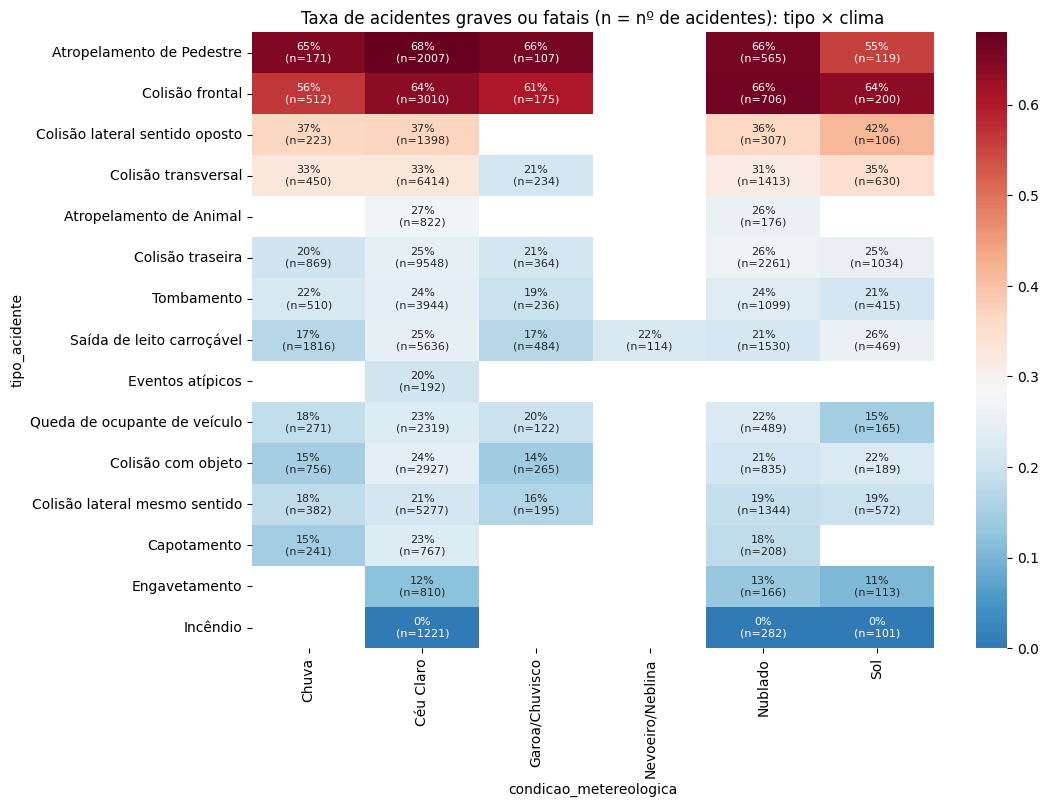

                        count      mean
condicao_metereologica                 
Céu Claro                2007  0.680120
Sol                       119  0.554622


In [ ]:
def mapa_calor_n(dados, linha, coluna, minimo=100, titulo=None, tamanho=(11, 8)):
    taxa_pivot = dados.pivot_table(index=linha, columns=coluna,
                                   values='grave_ou_fatal', aggfunc='mean')
    total_pivot = dados.pivot_table(index=linha, columns=coluna,
                                    values='grave_ou_fatal', aggfunc='count')

    taxa_pivot = taxa_pivot.where(total_pivot >= minimo)
    taxa_pivot = taxa_pivot.dropna(how='all').dropna(axis=1, how='all')
    taxa_pivot = taxa_pivot.loc[taxa_pivot.mean(axis=1).sort_values(ascending=False).index]
    total_pivot = total_pivot.reindex(index=taxa_pivot.index, columns=taxa_pivot.columns)

    rotulos = taxa_pivot.copy().astype(object)
    for i in taxa_pivot.index:
        for j in taxa_pivot.columns:
            if pd.notna(taxa_pivot.loc[i, j]):
                rotulos.loc[i, j] = f"{taxa_pivot.loc[i, j]:.0%}\n(n={int(total_pivot.loc[i, j])})"
            else:
                rotulos.loc[i, j] = ""

    plt.figure(figsize=tamanho)
    sns.heatmap(taxa_pivot, annot=rotulos, fmt='', cmap='RdBu_r',
                center=taxa_geral, annot_kws={'size': 8})
    plt.title(titulo or f'Taxa de acidentes graves ou fatais: {linha} × {coluna}')
    plt.show()

mapa_calor_n(base, 'tipo_acidente', 'condicao_metereologica',
             titulo='Taxa de acidentes graves ou fatais (n = nº de acidentes): tipo × clima')

print(df[(df['tipo_acidente'] == 'Atropelamento de Pedestre') &
         (df['condicao_metereologica'].isin(['Sol', 'Céu Claro']))]
        .groupby('condicao_metereologica')['grave_ou_fatal'].agg(['count', 'mean']))

                                      combinacao  total  graves_fatais  \
4          Atropelamento de Pedestre + Amanhecer    141            103   
6        Atropelamento de Pedestre + Plena Noite   1687           1225   
16                   Colisão frontal + Amanhecer    295            206   
18                 Colisão frontal + Plena Noite   2067           1321   
19                   Colisão frontal + Pleno dia   2111           1308   
17                   Colisão frontal + Anoitecer    266            163   
5          Atropelamento de Pedestre + Anoitecer    190            115   
7          Atropelamento de Pedestre + Pleno dia   1039            610   
25    Colisão lateral sentido oposto + Anoitecer    100             40   
26  Colisão lateral sentido oposto + Plena Noite    836            320   

        taxa     excesso  
4   0.730496   63.160584  
6   0.726141  748.339754  
16  0.698305  122.648030  
18  0.639090  736.971115  
19  0.619612  711.538957  
17  0.612782   87.84195

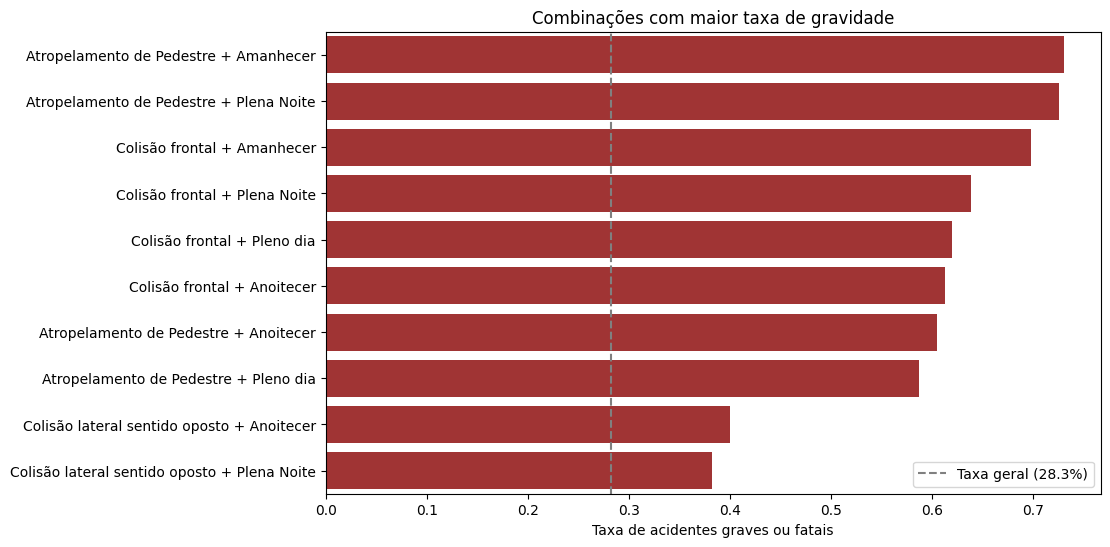

In [ ]:
def top_combinacoes(dados, col1, col2, minimo=100, n=10, ordenar_por='taxa'):
    tabela = taxa_por(dados, [col1, col2], minimo)
    tabela['excesso'] = tabela['graves_fatais'] - tabela['total'] * taxa_geral
    tabela['combinacao'] = tabela[col1] + ' + ' + tabela[col2]
    return tabela.sort_values(ordenar_por, ascending=False).head(n)

top = top_combinacoes(df, 'tipo_acidente', 'fase_dia')
print(top[['combinacao', 'total', 'graves_fatais', 'taxa', 'excesso']])

plt.figure(figsize=(10, 6))
sns.barplot(data=top, y='combinacao', x='taxa', color='firebrick')
plt.axvline(taxa_geral, linestyle='--', color='gray', label=f'Taxa geral ({taxa_geral:.1%})')
plt.xlabel('Taxa de acidentes graves ou fatais')
plt.ylabel('')
plt.title('Combinações com maior taxa de gravidade')
plt.legend()
plt.show()

In [ ]:
top = top_combinacoes(df, 'tipo_acidente', 'fase_dia', ordenar_por='excesso')
print(top)

                     tipo_acidente     fase_dia  total  graves_fatais  \
6        Atropelamento de Pedestre  Plena Noite   1687           1225   
18                 Colisão frontal  Plena Noite   2067           1321   
19                 Colisão frontal    Pleno dia   2111           1308   
7        Atropelamento de Pedestre    Pleno dia   1039            610   
30             Colisão transversal  Plena Noite   2560            940   
31             Colisão transversal    Pleno dia   5836           1803   
16                 Colisão frontal    Amanhecer    295            206   
27  Colisão lateral sentido oposto    Pleno dia   1090            399   
17                 Colisão frontal    Anoitecer    266            163   
26  Colisão lateral sentido oposto  Plena Noite    836            320   

        taxa     dif_pp     razao     excesso  \
6   0.726141  44.359203  2.569965  748.339754   
18  0.639090  35.654142  2.261874  736.971115   
19  0.619612  33.706251  2.192935  711.538957   


Modelos

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

modelo = RandomForestClassifier(random_state=50) #cria o modelo base
modelo.fit(x_train_encoded, y_train) #treina o modelo usando apenas os dados de treino

y_pred = modelo.predict(x_test_encoded) #faz as previsões usando o conjunto de teste

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred)) #mostra os acertos e erros divididos por classe em uma matriz de confusão

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred)) #mostra Precision, Recall e F1-Score para avaliar o desbalanceamento

Matriz de Confusão:
[[9414  993]
 [3031 1068]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.76      0.90      0.82     10407
           1       0.52      0.26      0.35      4099

    accuracy                           0.72     14506
   macro avg       0.64      0.58      0.59     14506
weighted avg       0.69      0.72      0.69     14506



In [ ]:
modelo_balanceado = RandomForestClassifier(random_state=50, class_weight='balanced') #cria o modelo dando mais peso aos erros da classe minoritária
modelo_balanceado.fit(x_train_encoded, y_train) #treina o modelo balanceado usando apenas os dados de treino

y_pred_balanceado = modelo_balanceado.predict(x_test_encoded) #faz as previsões usando o conjunto de teste

print("Matriz de Confusão (Balanceado):")
print(confusion_matrix(y_test, y_pred_balanceado)) #mostra os acertos e erros atualizados por classe em uma matriz de confusão

print("\nRelatório de Classificação (Balanceado):")
print(classification_report(y_test, y_pred_balanceado)) #mostra as novas métricas de Precision, Recall e F1-Score

Matriz de Confusão (Balanceado):
[[7269 3138]
 [2071 2028]]

Relatório de Classificação (Balanceado):
              precision    recall  f1-score   support

           0       0.78      0.70      0.74     10407
           1       0.39      0.49      0.44      4099

    accuracy                           0.64     14506
   macro avg       0.59      0.60      0.59     14506
weighted avg       0.67      0.64      0.65     14506



In [ ]:
modelo_rf_sem_peso = RandomForestClassifier(random_state=50, class_weight=None) #rf sem ajuste de peso
modelo_rf_sem_peso.fit(x_train_encoded, y_train) #treina o modelo sem balanceamento

modelo_rf_com_peso = RandomForestClassifier(random_state=50, class_weight='balanced') #rf com ajuste de peso
modelo_rf_com_peso.fit(x_train_encoded, y_train) #treina o modelo com balanceamento

importancias_rf_com_peso = pd.Series(modelo_rf_com_peso.feature_importances_, index=x_train_encoded.columns) #importâncias do modelo balanceado

comparacao_rf = pd.DataFrame({ #cria um DataFrame unindo as importâncias dos dois rf
    'Sem Ajuste de Peso': modelo_rf_sem_peso.feature_importances_,
    'Com Ajuste (Balanced)': modelo_rf_com_peso.feature_importances_
}, index=x_train_encoded.columns) #define as colunas codificadas como índice

top_variaveis_rf = comparacao_rf.loc[importancias_rf_com_peso.nlargest(10).index] #10 principais variáveis do modelo balanceado

print("Comparação direta das Importâncias - Random Forest (Top 10 do balanceado):")
print(top_variaveis_rf)

Comparação direta das Importâncias - Random Forest (Top 10 do balanceado):
                                         Sem Ajuste de Peso  \
tipo_acidente_Colisão frontal                      0.095422   
tipo_acidente_Atropelamento de Pedestre            0.069160   
condicao_metereologica_Céu Claro                   0.033504   
dia_semana_sexta-feira                             0.031056   
dia_semana_sábado                                  0.030094   
dia_semana_terça-feira                             0.029504   
dia_semana_segunda-feira                           0.028937   
dia_semana_quarta-feira                            0.028712   
condicao_metereologica_Nublado                     0.030326   
tipo_acidente_Incêndio                             0.016167   

                                         Com Ajuste (Balanced)  
tipo_acidente_Colisão frontal                         0.080618  
tipo_acidente_Atropelamento de Pedestre               0.057608  
condicao_metereologica_Céu Claro    

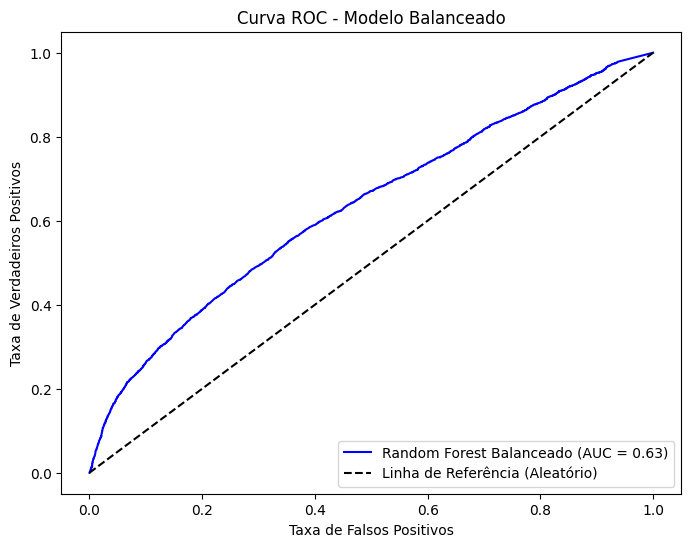

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob_balanceado = modelo_balanceado.predict_proba(x_test_encoded)[:, 1] #retorna as probabilidades preditas pra classe minoritária
auc_score = roc_auc_score(y_test, y_prob_balanceado) #calcula o valor de AUC

fpr, tpr, thresholds = roc_curve(y_test, y_prob_balanceado) #calcula os pontos da curva ROC (falsos positivos e verdadeiros positivos)

#criando o grafico
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest Balanceado (AUC = {auc_score:.2f})', color='blue') #plota a linha da curva ROC com o valor da AUC
plt.plot([0, 1], [0, 1], 'k--', label='Linha de Referência (Aleatório)')  # Plota a linha tracejada de um classificador aleatório
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC - Modelo Balanceado')
plt.legend(loc='lower right')
plt.show(block=True)

2-

In [ ]:
from sklearn.linear_model import LogisticRegression

modelo_logistica = LogisticRegression(random_state=50) #cria a regressão logística
modelo_logistica.fit(x_train_encoded, y_train) #treina o modelo usando apenas os dados de treino

y_pred_log = modelo_logistica.predict(x_test_encoded) #faz as previsões no conjunto de teste

print("Matriz de Confusão (Regressão Logística):")
print(confusion_matrix(y_test, y_pred_log)) #mostra os acertos e erros em uma matriz de confusão

print("\nRelatório de Classificação (Regressão Logística):")
print(classification_report(y_test, y_pred_log)) #mostra as métricas detalhadas

Matriz de Confusão (Regressão Logística):
[[9885  522]
 [3120  979]]

Relatório de Classificação (Regressão Logística):
              precision    recall  f1-score   support

           0       0.76      0.95      0.84     10407
           1       0.65      0.24      0.35      4099

    accuracy                           0.75     14506
   macro avg       0.71      0.59      0.60     14506
weighted avg       0.73      0.75      0.70     14506



In [ ]:
modelo_logistica = LogisticRegression(random_state=50, class_weight='balanced', max_iter=1000) #cria a regressão logística balanceada
modelo_logistica.fit(x_train_encoded, y_train) #treina o modelo usando apenas os dados de treino

y_pred_log = modelo_logistica.predict(x_test_encoded) #faz as previsões no conjunto de teste

print("Matriz de Confusão (Regressão Logística):")
print(confusion_matrix(y_test, y_pred_log)) #mostra os acertos e erros em uma matriz de confusão

print("\nRelatório de Classificação (Regressão Logística):")
print(classification_report(y_test, y_pred_log)) #mostra as métricas detalhadas

Matriz de Confusão (Regressão Logística):
[[7687 2720]
 [1938 2161]]

Relatório de Classificação (Regressão Logística):
              precision    recall  f1-score   support

           0       0.80      0.74      0.77     10407
           1       0.44      0.53      0.48      4099

    accuracy                           0.68     14506
   macro avg       0.62      0.63      0.62     14506
weighted avg       0.70      0.68      0.69     14506



In [ ]:
modelo_sem_peso = LogisticRegression(random_state=50, class_weight=None, max_iter=1000) #modelo sem ajuste de peso
modelo_sem_peso.fit(x_train_encoded, y_train) #treina o modelo sem balanceamento

modelo_com_peso = LogisticRegression(random_state=50, class_weight='balanced', max_iter=1000) #modelo com ajuste de peso
modelo_com_peso.fit(x_train_encoded, y_train) #treina o modelo com balanceamento

importancias_com_peso = pd.Series(modelo_com_peso.coef_[0], index=x_train_encoded.columns) #coeficientes do modelo balanceado

comparacao_coef = pd.DataFrame({ #cria um DataFrame unindo os dois conjuntos de coeficientes
    'Sem Ajuste de Peso': modelo_sem_peso.coef_[0], #coeficientes do modelo padrão
    'Com Ajuste (Balanced)': modelo_com_peso.coef_[0] #coeficientes do modelo balanceado
}, index=x_train_encoded.columns) #define as colunas codificadas como índice

top_variaveis = comparacao_coef.loc[importancias_com_peso.nlargest(10).index] #10 principais variáveis do modelo com peso

print("Comparação direta dos coeficientes (Top 10 do modelo balanceado):")
print(top_variaveis)

Comparação direta dos coeficientes (Top 10 do modelo balanceado):
                                              Sem Ajuste de Peso  \
tipo_acidente_Atropelamento de Pedestre                 1.593949   
tipo_acidente_Colisão frontal                           1.532662   
causa_acidente_Pedestre andava na pista                 0.639477   
tipo_acidente_Colisão lateral sentido oposto            0.538122   
tipo_acidente_Colisão transversal                       0.439326   
causa_acidente_Entrada inopinada do pedestre            0.408633   
causa_acidente_Ultrapassagem Indevida                   0.405508   
causa_acidente_Transitar no Acostamento                 0.409618   
causa_acidente_Transitar na contramão                   0.344195   
causa_acidente_Mal súbito do condutor                   0.317108   

                                              Com Ajuste (Balanced)  
tipo_acidente_Atropelamento de Pedestre                    1.649065  
tipo_acidente_Colisão frontal                

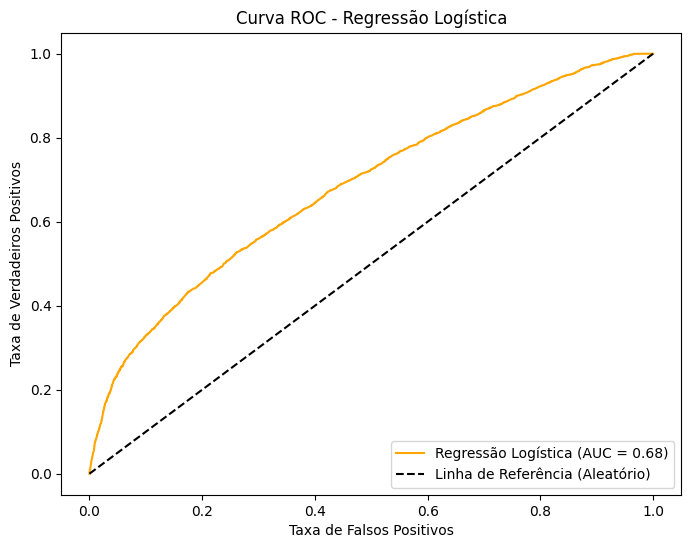

In [ ]:
y_prob_log = modelo_logistica.predict_proba(x_test_encoded)[:, 1] #pega as probabilidades preditas para a classe minoritária
auc_score_log = roc_auc_score(y_test, y_prob_log) #calcula o valor da auc da regressão logística

fpr_log, tpr_log, thresholds_log = roc_curve(y_test, y_prob_log) #calcula os pontos da curva roc (falsos e verdadeiros positivos)

plt.figure(figsize=(8, 6))
plt.plot(fpr_log, tpr_log, label=f'Regressão Logística (AUC = {auc_score_log:.2f})', color='orange') #plota a curva roc com o valor da auc
plt.plot([0, 1], [0, 1], 'k--', label='Linha de Referência (Aleatório)')  #plota a linha tracejada de referência aleatória
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC - Regressão Logística')
plt.legend(loc='lower right')
plt.show(block=True)

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score

pred_train = modelo_logistica.predict(x_train_encoded)
pred_test = modelo_logistica.predict(x_test_encoded)

print("=== TREINO ===")
print(classification_report(y_train, pred_train))
print("AUC treino:", roc_auc_score(y_train, modelo_logistica.predict_proba(x_train_encoded)[:, 1]))

print("=== TESTE ===")
print(classification_report(y_test, pred_test))
print("AUC teste:", roc_auc_score(y_test, modelo_logistica.predict_proba(x_test_encoded)[:, 1]))

=== TREINO ===
              precision    recall  f1-score   support

           0       0.80      0.73      0.76     41629
           1       0.44      0.52      0.48     16394

    accuracy                           0.67     58023
   macro avg       0.62      0.63      0.62     58023
weighted avg       0.69      0.67      0.68     58023

AUC treino: 0.678790127434161
=== TESTE ===
              precision    recall  f1-score   support

           0       0.80      0.74      0.77     10407
           1       0.44      0.53      0.48      4099

    accuracy                           0.68     14506
   macro avg       0.62      0.63      0.62     14506
weighted avg       0.70      0.68      0.69     14506

AUC teste: 0.6842689181210322


3-

In [ ]:
from sklearn.tree import DecisionTreeClassifier

modelo_dt_sem_peso = DecisionTreeClassifier(random_state=50, class_weight=None) #cria o modelo
modelo_dt_sem_peso.fit(x_train_encoded, y_train) #treina o modelo

y_pred_dt = modelo_dt_sem_peso.predict(x_test_encoded) #faz as previsões no conjunto de teste

print("Matriz de Confusão (DecisionTree):")
print(confusion_matrix(y_test, y_pred_dt)) #mostra os acertos e erros da árvore

print("\nRelatório de Classificação (DecisionTree):")
print(classification_report(y_test, y_pred_dt)) #mostra as métricas detalhadas da árvore

Matriz de Confusão (DecisionTree):
[[9473  934]
 [3102  997]]

Relatório de Classificação (DecisionTree):
              precision    recall  f1-score   support

           0       0.75      0.91      0.82     10407
           1       0.52      0.24      0.33      4099

    accuracy                           0.72     14506
   macro avg       0.63      0.58      0.58     14506
weighted avg       0.69      0.72      0.68     14506



In [ ]:
modelo_dt_com_peso = DecisionTreeClassifier(random_state=50, class_weight='balanced') #cria o modelo com ajuste de peso
modelo_dt_com_peso.fit(x_train_encoded, y_train) #treina o modelo

y_pred_dt_peso = modelo_dt_com_peso.predict(x_test_encoded) #faz as previsões no conjunto de teste

print("Matriz de Confusão (DecisionTree - Com Peso):")
print(confusion_matrix(y_test, y_pred_dt_peso)) #mstra os acertos e erros do modelo

print("\nRelatório de Classificação (DecisionTree - Com Peso):")
print(classification_report(y_test, y_pred_dt_peso)) #ostra as métricas detalhadas do modelo

Matriz de Confusão (DecisionTree - Com Peso):
[[6740 3667]
 [1882 2217]]

Relatório de Classificação (DecisionTree - Com Peso):
              precision    recall  f1-score   support

           0       0.78      0.65      0.71     10407
           1       0.38      0.54      0.44      4099

    accuracy                           0.62     14506
   macro avg       0.58      0.59      0.58     14506
weighted avg       0.67      0.62      0.63     14506



In [ ]:
importancias_dt_com_peso = pd.Series(modelo_dt_com_peso.feature_importances_, index=x_train_encoded.columns) #pega as importâncias do modelo com ajuste

comparacao_dt = pd.DataFrame({ #cria um DataFrame unindo as importâncias dos dois modelos
    'Sem Ajuste de Peso': modelo_dt_sem_peso.feature_importances_, #adiciona as importâncias do modelo sem ajuste
    'Com Ajuste (Balanced)': modelo_dt_com_peso.feature_importances_ #adiciona as importâncias do modelo com ajuste
}, index=x_train_encoded.columns) #define as colunas codificadas como índice

top_variaveis_dt = comparacao_dt.loc[importancias_dt_com_peso.nlargest(10).index] #seleciona as 10 principais variáveis do modelo com ajuste

print("Comparação direta das Importâncias - Árvore de Decisão (Top 10 do balanceado):")
print(top_variaveis_dt)

Comparação direta das Importâncias - Árvore de Decisão (Top 10 do balanceado):
                                         Sem Ajuste de Peso  \
tipo_acidente_Colisão frontal                      0.150615   
tipo_acidente_Atropelamento de Pedestre            0.130882   
tipo_acidente_Incêndio                             0.024837   
dia_semana_terça-feira                             0.026569   
fase_dia_Plena Noite                               0.026314   
dia_semana_quinta-feira                            0.029139   
condicao_metereologica_Céu Claro                   0.028574   
condicao_metereologica_Nublado                     0.028719   
dia_semana_sábado                                  0.025537   
dia_semana_segunda-feira                           0.025644   

                                         Com Ajuste (Balanced)  
tipo_acidente_Colisão frontal                         0.128247  
tipo_acidente_Atropelamento de Pedestre               0.113476  
tipo_acidente_Incêndio          

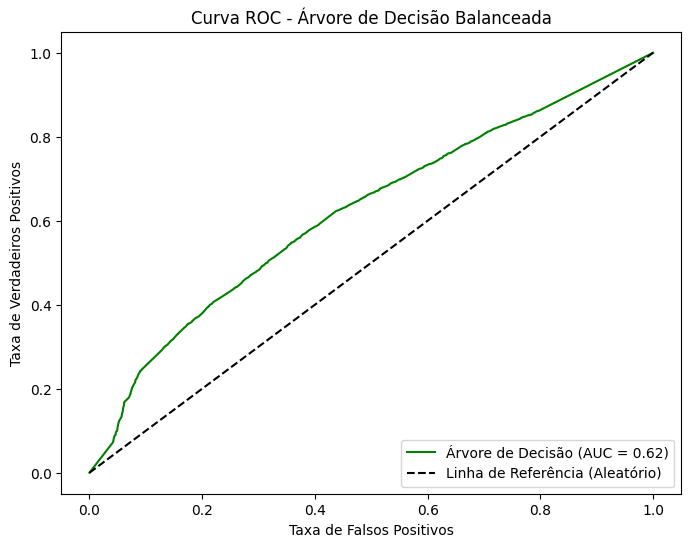

In [ ]:
y_prob_dt = modelo_dt_com_peso.predict_proba(x_test_encoded)[:, 1] #probabilidades preditas para a classe minoritária
auc_score_dt = roc_auc_score(y_test, y_prob_dt) #alcula o valor de auc

fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_prob_dt) #calcula os pontos da curva roc

plt.figure(figsize=(8, 6))
plt.plot(fpr_dt, tpr_dt, label=f'Árvore de Decisão (AUC = {auc_score_dt:.2f})', color='green') #plota a curva ROC
plt.plot([0, 1], [0, 1], 'k--', label='Linha de Referência (Aleatório)') #plota a linha de referência aleatória
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC - Árvore de Decisão Balanceada')
plt.legend(loc='lower right')
plt.show(block=True)

4-

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

modelo_gb_sem_peso = GradientBoostingClassifier(random_state=50) #cria o modelo
modelo_gb_sem_peso.fit(x_train_encoded, y_train) #treina o modelo com os dados de treino

y_pred_gb = modelo_gb_sem_peso.predict(x_test_encoded) #faz as previsões no conjunto de teste

print("Matriz de Confusão (Gradient Boosting - Sem Peso):")
print(confusion_matrix(y_test, y_pred_gb)) #mstra os acertos e erros do modelo

print("\nRelatório de Classificação (Gradient Boosting - Sem Peso):")
print(classification_report(y_test, y_pred_gb))

Matriz de Confusão (Gradient Boosting - Sem Peso):
[[9921  486]
 [3153  946]]

Relatório de Classificação (Gradient Boosting - Sem Peso):
              precision    recall  f1-score   support

           0       0.76      0.95      0.85     10407
           1       0.66      0.23      0.34      4099

    accuracy                           0.75     14506
   macro avg       0.71      0.59      0.59     14506
weighted avg       0.73      0.75      0.70     14506



In [ ]:
from sklearn.utils.class_weight import compute_sample_weight #função pra calcular os pesos das amostras

pesos_amostras = compute_sample_weight('balanced', y_train) #alcula os pesos balanceados para as amostras
modelo_gb_com_peso = GradientBoostingClassifier(random_state=50) #cria o modelo
modelo_gb_com_peso.fit(x_train_encoded, y_train, sample_weight=pesos_amostras) #treina o modelo usando os pesos balanceados

y_pred_gb_peso = modelo_gb_com_peso.predict(x_test_encoded) #faz as previsões no conjunto de teste

print("Matriz de Confusão (Gradient Boosting - Com Peso):")
print(confusion_matrix(y_test, y_pred_gb_peso)) #mostra os acertos e erros do modelo balanceado

print("\nRelatório de Classificação (Gradient Boosting - Com Peso):")
print(classification_report(y_test, y_pred_gb_peso)) # métricas detalhadas do modelo balanceado

Matriz de Confusão (Gradient Boosting - Com Peso):
[[7872 2535]
 [2033 2066]]

Relatório de Classificação (Gradient Boosting - Com Peso):
              precision    recall  f1-score   support

           0       0.79      0.76      0.78     10407
           1       0.45      0.50      0.47      4099

    accuracy                           0.69     14506
   macro avg       0.62      0.63      0.63     14506
weighted avg       0.70      0.69      0.69     14506



In [ ]:
importancias_gb_com_peso = pd.Series(modelo_gb_com_peso.feature_importances_, index=x_train_encoded.columns) #extrai as importâncias do modelo balanceado

comparacao_gb = pd.DataFrame({ #cria um DataFrame unindo as importâncias dos dois modelos
    'Sem Ajuste de Peso': modelo_gb_sem_peso.feature_importances_, #adiciona as importâncias do modelo padrão
    'Com Ajuste (Sample Weight)': modelo_gb_com_peso.feature_importances_ #adiciona as importâncias do modelo com pesos de amostra
}, index=x_train_encoded.columns) #define as colunas codificadas como índice

top_variaveis_gb = comparacao_gb.loc[importancias_gb_com_peso.nlargest(10).index] #10 principais variáveis do modelo com peso

print("Comparação direta das Importâncias - Gradient Boosting (Top 10 do balanceado):")
print(top_variaveis_gb)

Comparação direta das Importâncias - Gradient Boosting (Top 10 do balanceado):
                                                 Sem Ajuste de Peso  \
tipo_acidente_Colisão frontal                              0.372309   
tipo_acidente_Atropelamento de Pedestre                    0.323035   
tipo_acidente_Incêndio                                     0.063971   
tipo_acidente_Colisão transversal                          0.044924   
tipo_acidente_Colisão lateral sentido oposto               0.022051   
fase_dia_Pleno dia                                         0.015329   
tipo_acidente_Engavetamento                                0.008853   
causa_acidente_Ingestão de álcool pelo condutor            0.009151   
causa_acidente_Transitar na contramão                      0.016045   
condicao_metereologica_Chuva                               0.009534   

                                                 Com Ajuste (Sample Weight)  
tipo_acidente_Colisão frontal                                

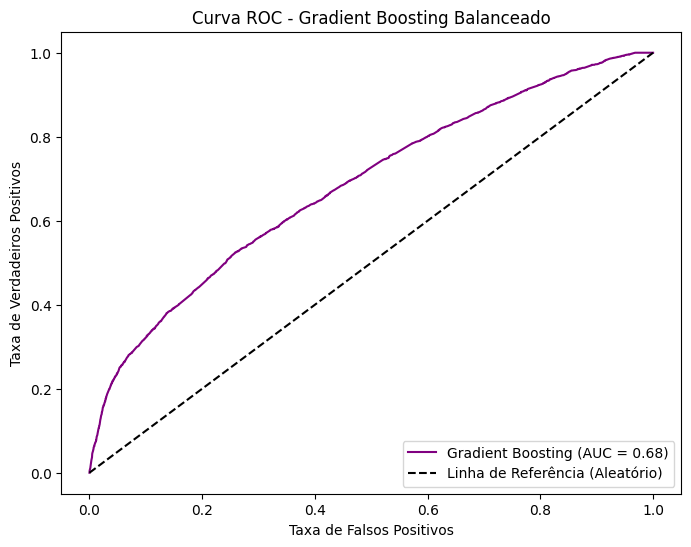

In [ ]:
y_prob_gb = modelo_gb_com_peso.predict_proba(x_test_encoded)[:, 1] #obtém as probabilidades preditas para a classe positiva
auc_score_gb = roc_auc_score(y_test, y_prob_gb) #calcula o valor de auc

fpr_gb, tpr_gb, thresholds_gb = roc_curve(y_test, y_prob_gb) #calcula os pontos da curva roc

plt.figure(figsize=(8, 6))
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {auc_score_gb:.2f})', color='purple') #plota a curva roc
plt.plot([0, 1], [0, 1], 'k--', label='Linha de Referência (Aleatório)') #plota a linha de referência aleatória
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC - Gradient Boosting Balanceado')
plt.legend(loc='lower right')
plt.show(block=True)